# Molecular Dynamics Analysis
This notebook reads output files generated by Fortran, performs statistical analysis (running averages, equilibration cutoffs), and plots the Radial Distribution Function (RDF), energy convergence, and pressure convergence.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Names of the files generated by Fortran
file_rdf = "../simulation/rdf_output.dat"
file_energy = "../simulation/energy-leap.dat"
file_pressure = "../simulation/pressure.dat"

## 1. Data Loading and Convergence Analysis
We load the data, compute the running averages to observe stabilization over time, and discard the initial thermalization phase (first 20%) for rigorous equilibrium averages.

In [2]:
# ---------------------------------------------------------
# 1. Data loading
# ---------------------------------------------------------
# RDF: r (col 0), g(r) (col 1)
data_rdf = np.loadtxt(file_rdf)
r = data_rdf[:, 0]
g_r = data_rdf[:, 1]

# Energy: time (col 0), total energy (col 1)
data_energy = np.loadtxt(file_energy)
time = data_energy[:, 0]
energy = data_energy[:, 1]

# Pressure: time (col 0), pressure (col 1)
# (It is assumed that the time array length is the same as for energy)
data_pressure = np.loadtxt(file_pressure)
pressure = data_pressure[:, 1]

# ---------------------------------------------------------
# 2. Convergence Analysis (Running averages)
# ---------------------------------------------------------
# The running average tells us how the mean value stabilizes over time
energy_running_avg = np.cumsum(energy) / np.arange(1, len(energy) + 1)
pressure_running_avg = np.cumsum(pressure) / np.arange(1, len(pressure) + 1)

# Print final results to the console (equilibrium averages)
# Note: For a strict equilibrium analysis, the "thermalization" phase 
# is usually discarded (e.g., the first 20% of the data).
term_cut = int(0.2 * len(energy))  # Discard the first 20% for a rigorous final average
mean_energy = np.mean(energy[term_cut:])
mean_pressure = np.mean(pressure[term_cut:])

print("-" * 50)
print("MEAN RESULTS (excluding initial 20% of thermalization):")
print(f"Total Energy Mean (E) : {mean_energy:.4f} (Reduced Units)")
print(f"Pressure Mean (P)       : {mean_pressure:.4f} (Reduced Units)")
print("-" * 50)

--------------------------------------------------
MEAN RESULTS (excluding initial 20% of thermalization):
Total Energy Mean (E) : -2266.6077 (Reduced Units)
Pressure Mean (P)       : 0.7001 (Reduced Units)
--------------------------------------------------


## 2. Plotting the Results
Here we generate and save the side-by-side plots for the Radial Distribution Function, Energy Convergence, and Pressure Convergence.

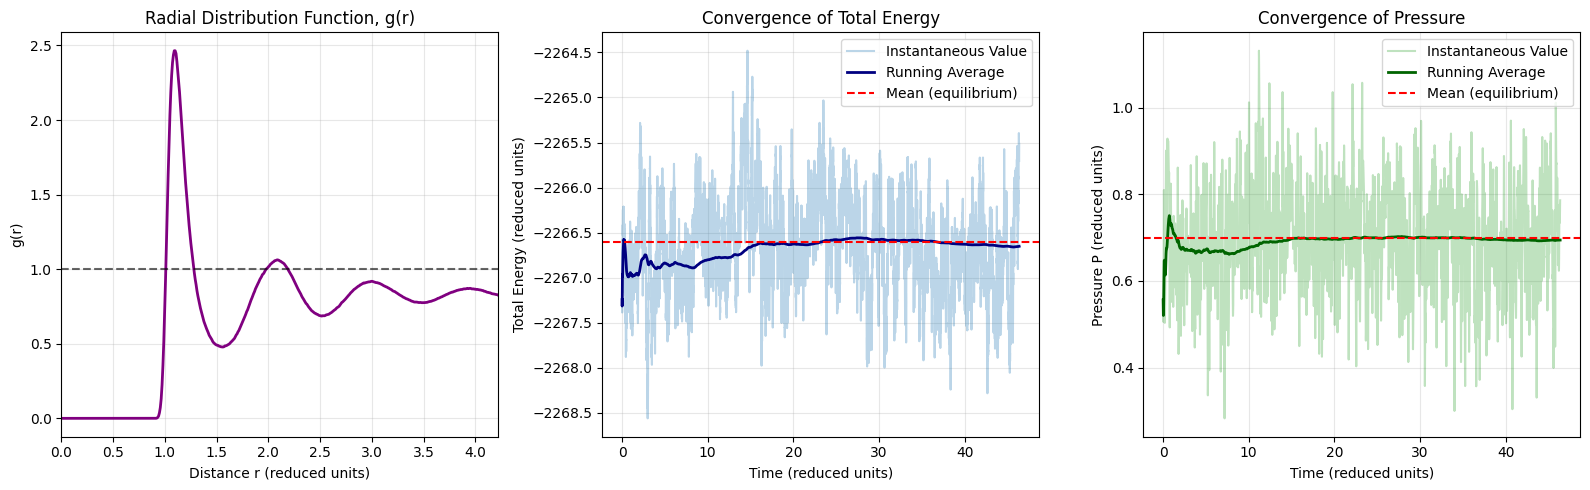

In [3]:
# ---------------------------------------------------------
# 3. Plot creation
# ---------------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Radial Distribution Function g(r)
axs[0].plot(r, g_r, color="purple", lw=2)
axs[0].axhline(y=1.0, color="black", linestyle="--", alpha=0.6)  # Asymptotic limit of g(r)
axs[0].set_title("Radial Distribution Function, g(r)")
axs[0].set_xlabel("Distance r (reduced units)")
axs[0].set_ylabel("g(r)")
axs[0].grid(True, alpha=0.3)
axs[0].set_xlim(0, max(r))

# Plot 2: Total Energy Convergence
axs[1].plot(time, energy, color="tab:blue", alpha=0.3, label="Instantaneous Value")
axs[1].plot(time, energy_running_avg, color="navy", lw=2, label="Running Average")
axs[1].axhline(y=mean_energy, color="red", linestyle="--", label="Mean (equilibrium)")
axs[1].set_title("Convergence of Total Energy")
axs[1].set_xlabel("Time (reduced units)")
axs[1].set_ylabel("Total Energy (reduced units)")
axs[1].legend()
axs[1].grid(True, alpha=0.3)

# Plot 3: Pressure Convergence
axs[2].plot(time, pressure, color="tab:green", alpha=0.3, label="Instantaneous Value")
axs[2].plot(time, pressure_running_avg, color="darkgreen", lw=2, label="Running Average")
axs[2].axhline(y=mean_pressure, color="red", linestyle="--", label="Mean (equilibrium)")
axs[2].set_title("Convergence of Pressure")
axs[2].set_xlabel("Time (reduced units)")
axs[2].set_ylabel("Pressure P (reduced units)")
axs[2].legend()
axs[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("md_analysis_results.png", dpi=300)
plt.show()